
# Experiment 2 — Learnable Shared/Private Capacity Allocation

### Goal

Experiment 1 showed that the **allocation theory itself** produces:

\[
\text{shared} \rightarrow \text{specialized}
\]

as capacity increases, and that the specialization threshold moves earlier when shortcut richness \(\tau\) or shared-space distortion \(\varepsilon\) increases.

This notebook asks the next question:

> **Does a trainable neural system exhibit the same capacity trade-off when we give it an explicit choice between a shared route and language-private routes?**

We deliberately build the neural environment so that the two theoretical quantities are independently controlled:

- **\(\varepsilon\): shared-route information loss.**  
  The shared pathway receives a lossy version of the semantic input. The private pathway sees the full semantic input. Because the task is parity, an erased bit makes the label irrecoverable, creating a genuine information-theoretic loss floor.

- **\(\tau\): shortcut richness.**  
  The private pathway receives an additional language-local cue \(c\) that predicts the invariant target with probability \(q\). Increasing \(q\) makes the private solution cheaper/easier without changing the underlying task.

The architecture has a fixed **capacity budget**

\[
N_{\text{units}} = s + Kp,
\]

where:

- \(s\) = width of the shared circuit;
- \(p\) = width of each language-private circuit;
- \(Kp\) = total private capacity.

For each total budget \(N_{\text{units}}\), we enumerate feasible allocations

\[
(s,p)
\quad\text{such that}\quad
s+Kp=N_{\text{units}},
\]

train each allocation, and ask which one achieves the lowest validation loss.

This is the first neural test of the theory.

> **Important:** allocation across architectures is controlled by the experimenter here. Within each architecture, the model learns its weights and a differentiable shared-vs-private routing gate. Experiment 2 therefore tests the theory in a trainable neural system without yet requiring a difficult neural architecture-search problem.



## 1. Experimental task

Each example begins with a latent semantic vector

\[
z\in\{-1,+1\}^d.
\]

The invariant target is its parity:

\[
y=\prod_{j=1}^{d}z_j.
\]

Every language expresses the same \(z\), so the underlying task is language-invariant.

### Shared route

The shared route receives an erased version

\[
\tilde z_j =
\begin{cases}
z_j & \text{with probability }1-e,\\
0 & \text{with probability }e.
\end{cases}
\]

For parity, if any bit is erased, the label is not recoverable from \(\tilde z\). Under squared loss with \(y\in\{-1,+1\}\), the Bayes-optimal loss floor is therefore

\[
\boxed{\varepsilon(e)=1-(1-e)^d.}
\]

This gives us a controlled realization of the theory's shared-space distortion.

### Private route

The private route receives the full \(z\) plus a language-local cue \(c\):

\[
c=
\begin{cases}
y & \text{with probability }q,\\
-y & \text{otherwise.}
\end{cases}
\]

A cue-only predictor has Bayes MSE

\[
4q(1-q).
\]

We therefore use the operational shortcut-strength proxy

\[
\boxed{\tau_{\mathrm{proxy}}=(2q-1)^2.}
\]

This is an experimental proxy for shortcut richness, not a claim that it is identical to the abstract Kolmogorov-style \(\tau\) in the theory.


In [1]:

import math
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

torch.set_num_threads(max(1, min(8, torch.get_num_threads())))


Device: cuda


In [2]:

@dataclass
class ExpConfig:
    # Task
    K: int = 4
    d_semantic: int = 4

    # Data
    n_train: int = 2000
    n_val: int = 1000
    batch_size: int = 256

    # Training
    epochs: int = 80
    lr: float = 1e-3
    weight_decay: float = 1e-4

    # Architecture sweep
    # Start small for the first run. Expand to [8,12,16,20,24] for the full sweep.
    budgets: tuple = (8, 12, 16)

    # Main factorial manipulation
    q_low_tau: float = 0.50
    q_high_tau: float = 0.80
    erase_low_eps: float = 0.05
    erase_high_eps: float = 0.20

    # Number of independent random seeds.
    # Use 1 initially; use 3 for the final paper run.
    seeds: tuple = (0,)

    # Training verbosity
    verbose: bool = True


CFG = ExpConfig()

print(asdict(CFG))


{'K': 4, 'd_semantic': 4, 'n_train': 2000, 'n_val': 1000, 'batch_size': 256, 'epochs': 80, 'lr': 0.001, 'weight_decay': 0.0001, 'budgets': (8, 12, 16), 'q_low_tau': 0.5, 'q_high_tau': 0.8, 'erase_low_eps': 0.05, 'erase_high_eps': 0.2, 'seeds': (0,), 'verbose': True}



## 2. Synthetic data generation


In [3]:

def make_dataset(n, K, d, q_shortcut, erase_prob, seed):
    """
    Generate an invariant parity task.

    z: full semantic content, shape [n, d]
    y: invariant target in {-1, +1}
    c: language-local shortcut cue
    lang: language identity

    shared_view:
        erased z + zeroed cue, so the shared route cannot use c.
    private_view:
        full z + c, so the language-private route has access to the shortcut.
    """
    rng = np.random.default_rng(seed)

    z = rng.choice([-1.0, 1.0], size=(n, d)).astype(np.float32)
    y = np.prod(z, axis=1).astype(np.float32)

    lang = rng.integers(0, K, size=n, endpoint=False)

    # Noisy language-local cue.
    cue = np.where(
        rng.random(n) < q_shortcut,
        y,
        -y
    ).astype(np.float32)

    # Shared route: independently erase semantic bits.
    keep = (rng.random((n, d)) >= erase_prob).astype(np.float32)
    shared_z = z * keep

    # The shared route does not get the shortcut.
    shared_x = np.concatenate(
        [shared_z, np.zeros((n, 1), dtype=np.float32)],
        axis=1
    )

    # Private route gets complete semantic content + local cue.
    private_x = np.concatenate(
        [z, cue[:, None]],
        axis=1
    )

    return (
        torch.from_numpy(shared_x),
        torch.from_numpy(private_x),
        torch.from_numpy(lang.astype(np.int64)),
        torch.from_numpy(y[:, None])
    )


def make_loaders(cfg, q_shortcut, erase_prob, seed):
    shared_tr, private_tr, lang_tr, y_tr = make_dataset(
        cfg.n_train, cfg.K, cfg.d_semantic,
        q_shortcut, erase_prob, seed
    )
    shared_va, private_va, lang_va, y_va = make_dataset(
        cfg.n_val, cfg.K, cfg.d_semantic,
        q_shortcut, erase_prob, seed + 100000
    )

    train = DataLoader(
        TensorDataset(shared_tr, private_tr, lang_tr, y_tr),
        batch_size=cfg.batch_size,
        shuffle=True
    )
    val = DataLoader(
        TensorDataset(shared_va, private_va, lang_va, y_va),
        batch_size=cfg.batch_size,
        shuffle=False
    )
    return train, val



### Controlled quantities for each condition

We report both the raw manipulation and the theoretically motivated proxies:

\[
\varepsilon_{\mathrm{Bayes}}
=
1-(1-e)^d
\]

and

\[
\tau_{\mathrm{proxy}}
=
(2q-1)^2.
\]



In [4]:

def epsilon_bayes(erase_prob, d):
    return 1.0 - (1.0 - erase_prob) ** d


def tau_proxy(q_shortcut):
    return (2.0 * q_shortcut - 1.0) ** 2


conditions = {
    "low_tau_low_eps": {
        "q": CFG.q_low_tau,
        "erase": CFG.erase_low_eps,
    },
    "high_tau_low_eps": {
        "q": CFG.q_high_tau,
        "erase": CFG.erase_low_eps,
    },
    "low_tau_high_eps": {
        "q": CFG.q_low_tau,
        "erase": CFG.erase_high_eps,
    },
    "high_tau_high_eps": {
        "q": CFG.q_high_tau,
        "erase": CFG.erase_high_eps,
    },
}

condition_table = pd.DataFrame([
    {
        "condition": name,
        "q": spec["q"],
        "erase_prob": spec["erase"],
        "tau_proxy": tau_proxy(spec["q"]),
        "epsilon_bayes": epsilon_bayes(spec["erase"], CFG.d_semantic),
    }
    for name, spec in conditions.items()
])

condition_table


,condition,q,erase_prob,tau_proxy,epsilon_bayes
0,low_tau_low_eps,0.5,0.05,0.00,0.185494
1,high_tau_low_eps,0.8,0.05,0.36,0.185494
2,low_tau_high_eps,0.5,0.20,0.00,0.590400
3,high_tau_high_eps,0.8,0.20,0.36,0.590400



## 3. Shared/private neural architecture

For an allocation \((s,p)\),

\[
N_{\text{units}}=s+Kp.
\]

There is:

- one shared MLP of width \(s\);
- one private MLP of width \(p\) for each language;
- one learned routing gate per language.

The model predicts

\[
\hat y_L
=
(1-g_L)\hat y_S
+
g_L\hat y_{P,L},
\]

where

\[
g_L=\sigma(a_L).
\]

Interpretation:

- \(g_L\approx0\): the language uses the shared route;
- \(g_L\approx1\): the language uses the private route.

The gates are intentionally tiny compared with the circuits and are not counted as meaningful capacity.


In [5]:

class TinyMLP(nn.Module):
    def __init__(self, input_dim, width):
        super().__init__()
        if width == 0:
            self.net = None
        else:
            self.net = nn.Sequential(
                nn.Linear(input_dim, width),
                nn.ReLU(),
                nn.Linear(width, 1)
            )

    def forward(self, x):
        if self.net is None:
            raise RuntimeError("Attempted to use a zero-width network.")
        return self.net(x)


class SharedPrivateModel(nn.Module):
    def __init__(self, K, input_dim, shared_width, private_width):
        super().__init__()

        if shared_width == 0 and private_width == 0:
            raise ValueError("At least one route must have nonzero width.")

        self.K = K
        self.shared_width = shared_width
        self.private_width = private_width

        self.shared = TinyMLP(input_dim, shared_width) if shared_width > 0 else None

        self.private = nn.ModuleList([
            TinyMLP(input_dim, private_width)
            for _ in range(K)
        ]) if private_width > 0 else None

        # Tiny per-language route-selection parameters.
        # sigmoid(gate_logits) = probability/weight on private route.
        self.gate_logits = nn.Parameter(torch.zeros(K))

    def forward(self, shared_x, private_x, lang, return_gate=False):
        n = shared_x.shape[0]

        if self.shared is not None:
            shared_pred = self.shared(shared_x)
        else:
            shared_pred = torch.zeros(
                (n, 1), device=shared_x.device, dtype=shared_x.dtype
            )

        if self.private is not None:
            private_pred = torch.empty(
                (n, 1), device=private_x.device, dtype=private_x.dtype
            )

            for L in range(self.K):
                idx = (lang == L)
                if idx.any():
                    private_pred[idx] = self.private[L](private_x[idx])
        else:
            private_pred = torch.zeros_like(shared_pred)

        gates = torch.sigmoid(self.gate_logits)[lang].unsqueeze(-1)

        if self.private is None:
            gates = torch.zeros_like(gates)
        elif self.shared is None:
            gates = torch.ones_like(gates)

        pred = (1.0 - gates) * shared_pred + gates * private_pred

        if return_gate:
            return pred, gates.squeeze(-1)
        return pred


def effective_unit_budget(shared_width, private_width, K):
    return shared_width + K * private_width


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)



## 4. Training and evaluation


In [6]:

def seed_everything(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def evaluate(model, loader, device=DEVICE, include_route_stats=True):
    model.eval()

    losses = []
    sq_errors = []
    all_gates = []
    all_langs = []

    for shared_x, private_x, lang, y in loader:
        shared_x = shared_x.to(device)
        private_x = private_x.to(device)
        lang = lang.to(device)
        y = y.to(device)

        pred, gates = model(
            shared_x, private_x, lang, return_gate=True
        )

        sq = (pred - y) ** 2
        losses.append(sq.mean().item())
        sq_errors.append(sq.detach().cpu())
        all_gates.append(gates.detach().cpu())
        all_langs.append(lang.detach().cpu())

    loss = float(np.mean(losses))

    result = {"loss": loss}

    if include_route_stats:
        gates = torch.cat(all_gates).numpy()
        langs = torch.cat(all_langs).numpy()

        for L in range(model.K):
            mask = langs == L
            result[f"gate_L{L}"] = float(gates[mask].mean()) if mask.any() else np.nan

        result["gate_mean"] = float(gates.mean())

    return result


def train_model(cfg, shared_width, private_width,
                q_shortcut, erase_prob, seed):
    seed_everything(seed)

    train_loader, val_loader = make_loaders(
        cfg, q_shortcut, erase_prob, seed
    )

    model = SharedPrivateModel(
        K=cfg.K,
        input_dim=cfg.d_semantic + 1,
        shared_width=shared_width,
        private_width=private_width
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=cfg.lr,
        weight_decay=cfg.weight_decay
    )

    history = []

    for epoch in range(cfg.epochs):
        model.train()

        train_losses = []

        for shared_x, private_x, lang, y in train_loader:
            shared_x = shared_x.to(DEVICE)
            private_x = private_x.to(DEVICE)
            lang = lang.to(DEVICE)
            y = y.to(DEVICE)

            pred = model(shared_x, private_x, lang)

            loss = ((pred - y) ** 2).mean()

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        if (epoch + 1) in {1, cfg.epochs} or (epoch + 1) % max(1, cfg.epochs // 4) == 0:
            val_metrics = evaluate(model, val_loader)
            history.append({
                "epoch": epoch + 1,
                "train_loss": float(np.mean(train_losses)),
                "val_loss": val_metrics["loss"],
                "gate_mean": val_metrics["gate_mean"],
            })

    final = evaluate(model, val_loader)

    result = {
        "shared_width": shared_width,
        "private_width": private_width,
        "unit_budget": effective_unit_budget(
            shared_width, private_width, cfg.K
        ),
        "parameters": count_parameters(model),
        "val_loss": final["loss"],
        "gate_mean": final["gate_mean"],
        "seed": seed,
        "q_shortcut": q_shortcut,
        "erase_prob": erase_prob,
    }

    for L in range(cfg.K):
        result[f"gate_L{L}"] = final[f"gate_L{L}"]

    return result, history, model



## 5. Architecture sweep

For a fixed unit budget \(N\), feasible allocations satisfy

\[
s+Kp=N.
\]

We train **every feasible allocation** and choose the one with minimum validation loss.

This is the neural analogue of Experiment 1's exact allocation optimization.

The primary outcome is

\[
p^*(N,\tau,\varepsilon),
\]

the empirically preferred amount of private capacity.


In [7]:

def feasible_allocations(budget, K):
    return [
        (budget - K * p, p)
        for p in range(budget // K + 1)
    ]


def run_condition(cfg, condition_name, spec, budgets=None, seeds=None):
    if budgets is None:
        budgets = cfg.budgets
    if seeds is None:
        seeds = cfg.seeds

    rows = []

    for seed in seeds:
        for budget in budgets:
            allocations = feasible_allocations(budget, cfg.K)

            for shared_width, private_width in allocations:
                if cfg.verbose:
                    print(
                        f"{condition_name:>18s} | "
                        f"N={budget:>2d} | "
                        f"s={shared_width:>2d} | "
                        f"p={private_width:>2d} | "
                        f"seed={seed}"
                    )

                result, _, _ = train_model(
                    cfg,
                    shared_width=shared_width,
                    private_width=private_width,
                    q_shortcut=spec["q"],
                    erase_prob=spec["erase"],
                    seed=seed
                )

                result["condition"] = condition_name
                result["tau_proxy"] = tau_proxy(spec["q"])
                result["epsilon_bayes"] = epsilon_bayes(
                    spec["erase"], cfg.d_semantic
                )
                rows.append(result)

    return pd.DataFrame(rows)


def select_best_allocations(results):
    sort_cols = ["condition", "unit_budget", "val_loss"]
    ordered = results.sort_values(sort_cols)
    best = (
        ordered
        .groupby(["condition", "unit_budget"], as_index=False)
        .first()
    )
    return best



## 6. Run the first neural sweep

The default configuration is deliberately small:

- \(K=4\) languages;
- budgets \([8,12,16]\);
- one seed;
- 80 epochs.

For the final paper run, increase the budget grid and use at least 3 seeds.


In [8]:

# This cell is the main experiment.
# Set RUN_FULL = True below to use a larger sweep.

RUN_FULL = False

if RUN_FULL:
    budgets_to_run = (8, 12, 16, 20, 24)
    seeds_to_run = (0, 1, 2)
else:
    budgets_to_run = CFG.budgets
    seeds_to_run = CFG.seeds

all_results = []

for condition_name, spec in conditions.items():
    condition_results = run_condition(
        CFG,
        condition_name,
        spec,
        budgets=budgets_to_run,
        seeds=seeds_to_run
    )
    all_results.append(condition_results)

results = pd.concat(all_results, ignore_index=True)

print("Total trained models:", len(results))
results.head()


   low_tau_low_eps | N= 8 | s= 8 | p= 0 | seed=0
   low_tau_low_eps | N= 8 | s= 4 | p= 1 | seed=0
   low_tau_low_eps | N= 8 | s= 0 | p= 2 | seed=0
   low_tau_low_eps | N=12 | s=12 | p= 0 | seed=0
   low_tau_low_eps | N=12 | s= 8 | p= 1 | seed=0
   low_tau_low_eps | N=12 | s= 4 | p= 2 | seed=0
   low_tau_low_eps | N=12 | s= 0 | p= 3 | seed=0
   low_tau_low_eps | N=16 | s=16 | p= 0 | seed=0
   low_tau_low_eps | N=16 | s=12 | p= 1 | seed=0
   low_tau_low_eps | N=16 | s= 8 | p= 2 | seed=0
   low_tau_low_eps | N=16 | s= 4 | p= 3 | seed=0
   low_tau_low_eps | N=16 | s= 0 | p= 4 | seed=0
  high_tau_low_eps | N= 8 | s= 8 | p= 0 | seed=0
  high_tau_low_eps | N= 8 | s= 4 | p= 1 | seed=0
  high_tau_low_eps | N= 8 | s= 0 | p= 2 | seed=0
  high_tau_low_eps | N=12 | s=12 | p= 0 | seed=0
  high_tau_low_eps | N=12 | s= 8 | p= 1 | seed=0
  high_tau_low_eps | N=12 | s= 4 | p= 2 | seed=0
  high_tau_low_eps | N=12 | s= 0 | p= 3 | seed=0
  high_tau_low_eps | N=16 | s=16 | p= 0 | seed=0
  high_tau_low_eps |

,shared_width,private_width,unit_budget,parameters,val_loss,gate_mean,seed,q_shortcut,erase_prob,gate_L0,gate_L1,gate_L2,gate_L3,condition,tau_proxy,epsilon_bayes
0,8,0,8,61,0.750419,0.000000,0,0.5,0.05,0.000000,0.000000,0.000000,0.000000,low_tau_low_eps,0.0,0.185494
1,4,1,8,65,0.951700,0.423931,0,0.5,0.05,0.401231,0.408914,0.437476,0.448698,low_tau_low_eps,0.0,0.185494
2,0,2,8,64,0.975129,1.000000,0,0.5,0.05,1.000000,1.000000,1.000000,1.000000,low_tau_low_eps,0.0,0.185494
3,12,0,12,89,0.351574,0.000000,0,0.5,0.05,0.000000,0.000000,0.000000,0.000000,low_tau_low_eps,0.0,0.185494
4,8,1,12,93,0.729928,0.373357,0,0.5,0.05,0.385204,0.359719,0.389243,0.360500,low_tau_low_eps,0.0,0.185494



## 7. Empirical allocation choices

For each condition and budget, select the allocation with the lowest validation loss.

The main plots are:

1. private width \(p^*\) vs. capacity;
2. mean private-route gate vs. capacity;
3. best validation loss vs. capacity.


In [9]:

best = select_best_allocations(results)

best[[
    "condition",
    "unit_budget",
    "shared_width",
    "private_width",
    "parameters",
    "val_loss",
    "gate_mean",
    "tau_proxy",
    "epsilon_bayes"
]].sort_values(["condition", "unit_budget"])


,condition,unit_budget,shared_width,private_width,parameters,val_loss,gate_mean,tau_proxy,epsilon_bayes
0,high_tau_high_eps,8,4,1,65,0.798763,0.493183,0.36,0.590400
1,high_tau_high_eps,12,0,3,92,0.673939,1.000000,0.36,0.590400
2,high_tau_high_eps,16,0,4,120,0.609055,1.000000,0.36,0.590400
3,high_tau_low_eps,8,8,0,61,0.750419,0.000000,0.36,0.185494
4,high_tau_low_eps,12,12,0,89,0.351574,0.000000,0.36,0.185494
5,high_tau_low_eps,16,16,0,117,0.424547,0.000000,0.36,0.185494
6,low_tau_high_eps,8,8,0,61,0.900794,0.000000,0.00,0.590400
7,low_tau_high_eps,12,12,0,89,0.786121,0.000000,0.00,0.590400
8,low_tau_high_eps,16,16,0,117,0.820692,0.000000,0.00,0.590400
9,low_tau_low_eps,8,8,0,61,0.750419,0.000000,0.00,0.185494


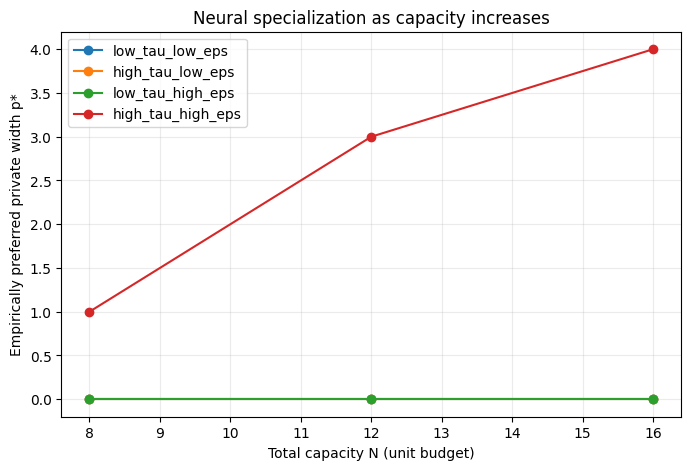

In [10]:

plt.figure(figsize=(8, 5))

for condition_name in conditions:
    sub = best[best["condition"] == condition_name].sort_values("unit_budget")
    plt.plot(
        sub["unit_budget"],
        sub["private_width"],
        marker="o",
        label=condition_name
    )

plt.xlabel("Total capacity N (unit budget)")
plt.ylabel("Empirically preferred private width p*")
plt.title("Neural specialization as capacity increases")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()


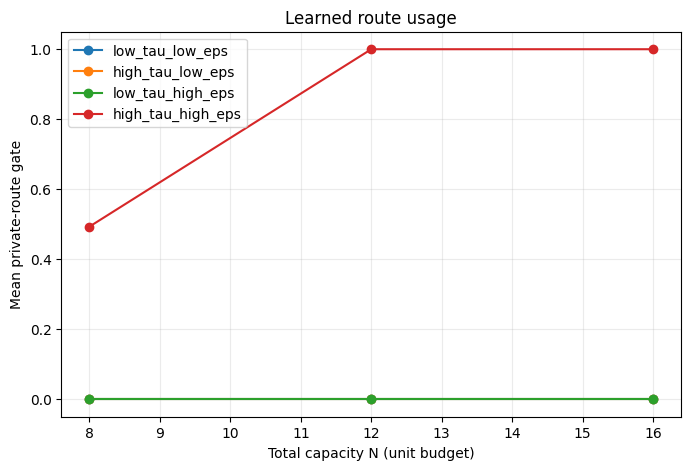

In [11]:

plt.figure(figsize=(8, 5))

for condition_name in conditions:
    sub = best[best["condition"] == condition_name].sort_values("unit_budget")
    plt.plot(
        sub["unit_budget"],
        sub["gate_mean"],
        marker="o",
        label=condition_name
    )

plt.xlabel("Total capacity N (unit budget)")
plt.ylabel("Mean private-route gate")
plt.title("Learned route usage")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()


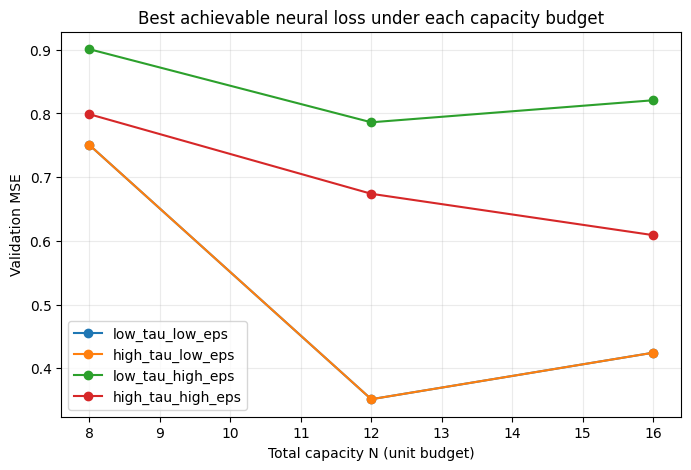

In [12]:

plt.figure(figsize=(8, 5))

for condition_name in conditions:
    sub = best[best["condition"] == condition_name].sort_values("unit_budget")
    plt.plot(
        sub["unit_budget"],
        sub["val_loss"],
        marker="o",
        label=condition_name
    )

plt.xlabel("Total capacity N (unit budget)")
plt.ylabel("Validation MSE")
plt.title("Best achievable neural loss under each capacity budget")
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()



## 8. The key test: do \(\tau\) and \(\varepsilon\) shift specialization?

For each condition, define the empirical specialization onset

\[
\hat N_{\mathrm{first}}
=
\min\{N:p^*(N)>0\}.
\]

We compare the four factorial conditions:

- low \(\tau\), low \(\varepsilon\);
- high \(\tau\), low \(\varepsilon\);
- low \(\tau\), high \(\varepsilon\);
- high \(\tau\), high \(\varepsilon\).

The theory predicts:

\[
\boxed{
\tau\uparrow \Rightarrow \hat N_{\mathrm{first}}\downarrow
}
\]

and

\[
\boxed{
\varepsilon\uparrow \Rightarrow \hat N_{\mathrm{first}}\downarrow.
}
\]


In [13]:

def empirical_first_specialization(best_df):
    rows = []

    for condition_name in best_df["condition"].unique():
        sub = best_df[
            best_df["condition"] == condition_name
        ].sort_values("unit_budget")

        private = sub[sub["private_width"] > 0]

        first = (
            float(private["unit_budget"].iloc[0])
            if len(private) else np.inf
        )

        row = {
            "condition": condition_name,
            "first_private_budget": first,
            "tau_proxy": float(sub["tau_proxy"].iloc[0]),
            "epsilon_bayes": float(sub["epsilon_bayes"].iloc[0]),
        }
        rows.append(row)

    return pd.DataFrame(rows).sort_values(
        ["first_private_budget", "condition"]
    )


onsets = empirical_first_specialization(best)
onsets


,condition,first_private_budget,tau_proxy,epsilon_bayes
0,high_tau_high_eps,8.0,0.36,0.590400
1,high_tau_low_eps,inf,0.36,0.185494
2,low_tau_high_eps,inf,0.00,0.590400
3,low_tau_low_eps,inf,0.00,0.185494



### Important interpretation

A successful result is **not** merely "private modules can help."

The desired pattern is an ordering:

\[
\hat N_{\mathrm{first}}
(\text{high }\tau,\text{ high }\varepsilon)
<
\hat N_{\mathrm{first}}
(\text{high }\tau,\text{ low }\varepsilon),
\]

and

\[
\hat N_{\mathrm{first}}
(\text{low }\tau,\text{ high }\varepsilon)
<
\hat N_{\mathrm{first}}
(\text{low }\tau,\text{ low }\varepsilon).
\]

That is the neural version of the theory's comparative statics.



# 9. Causal route-use checks

An allocation can contain private parameters without actually using them.

For the best model at each condition/budget we therefore want a causal check:

1. evaluate normally;
2. force the private gate to zero;
3. compare the loss increase.

If the private circuit has actually become functionally important, removing it should hurt performance.

For the final run, we should also test **private-expert swapping across languages**. If private computation genuinely becomes language-specific, replacing language \(L\)'s private module with another language's should increasingly hurt the relevant language.


In [14]:

@torch.no_grad()
def evaluate_forced_route(model, loader, route="normal", device=DEVICE):
    model.eval()
    losses = []

    old_gate = model.gate_logits.detach().clone()

    if route == "shared":
        model.gate_logits.data.fill_(-20.0)
    elif route == "private":
        model.gate_logits.data.fill_(20.0)
    elif route == "normal":
        pass
    else:
        raise ValueError(route)

    for shared_x, private_x, lang, y in loader:
        shared_x = shared_x.to(device)
        private_x = private_x.to(device)
        lang = lang.to(device)
        y = y.to(device)

        pred = model(shared_x, private_x, lang)
        losses.append(((pred - y) ** 2).mean().item())

    model.gate_logits.data.copy_(old_gate)
    return float(np.mean(losses))


def route_ablation_report(cfg, condition_name, spec,
                          budget, seed=0):
    # Find the best allocation for this condition/budget.
    rows = []
    for shared_width, private_width in feasible_allocations(
        budget, cfg.K
    ):
        result, _, model = train_model(
            cfg,
            shared_width,
            private_width,
            spec["q"],
            spec["erase"],
            seed
        )

        rows.append((result["val_loss"], shared_width, private_width, model))

    best_loss, s, p, best_model = min(rows, key=lambda x: x[0])

    _, val_loader = make_loaders(
        cfg, spec["q"], spec["erase"], seed
    )

    normal_loss = evaluate_forced_route(
        best_model, val_loader, route="normal"
    )
    shared_loss = evaluate_forced_route(
        best_model, val_loader, route="shared"
    )

    return {
        "condition": condition_name,
        "budget": budget,
        "shared_width": s,
        "private_width": p,
        "normal_loss": normal_loss,
        "forced_shared_loss": shared_loss,
        "private_ablation_penalty": shared_loss - normal_loss,
    }



## 10. Suggested final paper run

Once the small sweep behaves sensibly, use:

```python
RUN_FULL = True
```

with:

- budgets \([8,12,16,20,24]\);
- 3 seeds;
- then repeat the best/representative allocations with larger datasets.

The final analysis should report:

### A. Capacity effect

\[
N\uparrow
\Rightarrow
p^*(N)\uparrow
\]

or at minimum a delayed onset of \(p^*>0\).

### B. Shortcut effect

\[
\tau\uparrow
\Rightarrow
N^*\downarrow.
\]

### C. Shared-distortion effect

\[
\varepsilon\uparrow
\Rightarrow
N^*\downarrow.
\]

### D. Functional specialization

Private-route ablation should increasingly damage high-\(\tau\)/high-\(\varepsilon\) conditions.

If these effects do not appear, that is informative: it means the theoretical allocation model does not translate into neural optimization under this particular realization and we need to understand why before touching the PCFG.



# 11. What this experiment is — and is not

### This experiment tests

Whether the **capacity competition mechanism survives contact with a trainable neural system** when:

- shared capacity is genuinely reusable across languages;
- private capacity is genuinely replicated across languages;
- the shared route has a controlled information ceiling;
- the private route can exploit a controllable shortcut.

### It does not yet test

- real multilingual LLMs;
- Semantic Hub directly;
- Lim et al.'s logit-lens measurement;
- naturally occurring language typology;
- whether \(\tau\) can be estimated from real corpora.

Those are later experiments.

The most important result here is:

\[
\boxed{
\text{Does the neural model's empirically preferred allocation
move in the directions predicted by the theory?}
}
\]
